<a href="https://colab.research.google.com/github/moushi21/microduck_rl/blob/develop/microduck_jump_backlash_training_and_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install uv and Clone Repository
- Runtime check: Ensure the Colab runtime is set to NVIDIA L4 GPU (`Runtime` > `Change runtime type` > `L4 GPU`).
- Install `uv` for ultra-fast, reproducible dependency management.
- Clone the `microduck_rl` repository and enter the project directory.

In [ ]:
# Verify GPU environment
!nvidia-smi

!pip install uv
!git clone https://github.com/moushi21/microduck_rl.git
%cd microduck_rl

Wed Nov  4 10:08:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   42C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Setup Dependencies (PyTorch with CUDA Acceleration)
- Synchronize all project dependencies defined in `pyproject.toml` using `uv sync`.
- Automatically sets up MuJoCo Warp, rsl_rl (PPO), and CUDA-enabled PyTorch.
- Run a quick sanity check to verify that PyTorch detects the NVIDIA L4 GPU.

In [ ]:
!uv pip install --system torch torchvision --index-url https://download.pytorch.org/whl/cu121
!uv pip install --system -e .

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 124ms
Using Python 3.13.16 environment at: /usr
Resolved 133 packages in 1.17s
Prepared 54 packages in 31.02s
Uninstalled 17 packages in 501ms
Installed 54 packages in 219ms
 + bcrypt==5.0.0
 + better-actuator-models==1.0.1 (from git+https://github.com/Rhoban/bam.git@57d13ead53206a6bf0db3d66f86506ae8c2ce01a)
 + colorama==0.4.6
 - decorator==4.4.2
 + decorator==5.3.1
 + deprecated==3.0.1
 + fabric==3.2.3
 + gitdb==4.0.12
 + gitpython==3.2.1
 + glfw==2.11.0
 + invoke==2.2.1
 + jedi==0.20.1
 - matplotlib==3.10.0
 + matplotlib==3.11.2
 + mediapy==1.2.7
 + mjlab==1.3.0
 + mjlab-microduck==0.1.0 (from file:///content/microduck_rl)
 + mjviser==0.0.16
 + msgspec==0.22.0
 + mujoco==3.17.0
 + mujoco-warp==3.8.1
 - nvidia-cublas-cu12==12.9.2.10
 + nvidia-cublas-cu12==12.8.4.1
 - nvidia-cuda-cupti-cu12==12.9.79
 + nvidia-cuda-cupti-cu12==12.8.90
 - nvidia-cuda-nvrtc-cu12==12.9.86
 + nvidia-cuda-nvrtc-cu12==12.8.93
 - nvidia-cuda-runti

## 3. Verify Registered Task: `Mjlab-Jump-Flat-Backlash-MicroDuck`
- Inspect the live environment registry using `uv run list-envs`.
- Confirm that the newly implemented `Mjlab-Jump-Flat-Backlash-MicroDuck` task is successfully registered and available for training.

In [ ]:
!uv sync
!uv run list-envs

Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: .venv
Resolved 154 packages in 1ms
Prepared 117 packages in 10.67s
Installed 142 packages in 328ms
 + absl-py==2.3.1
 + annotated-doc==0.0.4
 + annotated-types==0.7.0
 + anyio==4.12.1
 + asttokens==3.0.1
 + bcrypt==5.0.0
 + better-actuator-models==1.0.1 (from git+https://github.com/Rhoban/bam.git@62bd8ce12154340be97e06f7f41a0ca8f116d967)
 + certifi==2026.1.4
 + cffi==2.0.0
 + charset-normalizer==3.4.4
 + click==8.3.1
 + cloudpickle==3.1.2
 + colorama==0.4.6
 + contourpy==1.3.3
 + cryptography==46.0.3
 + cycler==0.12.1
 + decorator==5.2.1
 + deprecated==1.3.1
 + docstring-parser==0.17.0
 + etils==1.13.0
 + executing==2.2.1
 + fabric==3.2.2
 + filelock==3.20.3
 + flatbuffers==25.12.19
 + fonttools==4.63.0
 + fsspec==2026.1.0
 + gitdb==4.0.12
 + gitpython==3.1.46
 + glfw==2.10.0
 + grpcio==1.76.0
 + h11==0.16.0
 + hf-xet==1.5.0
 + httpcore==1.0.9
 + httpx==0.28.1
 + huggingface-hub==1.15.0
 + idna==3

## 4. Configure WandB via Colab Secrets (Bypassing `wandb-core` Hang)
- Securely fetch the Weights & Biases API key from Colab Secrets (`userdata.get`) to avoid exposing credentials in code.
- Automatically sanitize inputs with `.strip()` to prevent authentication failures caused by invisible trailing spaces.
- **Robust workaround for the `wandb-core` (Go daemon) deadlock**: Bypasses `wandb.login()` entirely by injecting `WANDB_API_KEY` and `WANDB_SILENT` directly into `os.environ`, allowing `rsl_rl` to authenticate seamlessly without freezing.

In [ ]:
from google.colab import userdata
import os
try:
    # 1. Retrieve and sanitize API key
    api_key = userdata.get("WANDB_API_KEY").strip()

    # 2. Inject into environment (bypassing interactive login hang)
    os.environ["WANDB_API_KEY"] = api_key
    os.environ["WANDB_SILENT"] = "true"
    print("✓ Successfully configured WANDB_API_KEY in environment.")

except userdata.SecretNotFoundError:
    print("✗ Error: 'WANDB_API_KEY' is not registered in Colab Secrets (left sidebar 🔑 icon).")

✓ Successfully configured WANDB_API_KEY in environment.


## 5. Smoke Test (5-Iteration Rapid Verification)
- Run a minimal 5-iteration smoke test with 64 parallel environments (`--env.scene.num-envs 64 --agent.max_iterations 5`).
- Catches ~95% of configuration errors, NaN crashes, and tensor mismatches in seconds before launching full-scale training.
- Log in to your Weights & Biases web dashboard and verify that the run is created and streaming metrics (e.g., `Episode_Reward`, loss curves) successfully.

In [ ]:
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Jump-Flat-Backlash-MicroDuck \
  --env.scene.num-envs 64 \
  --agent.resume False \
  --agent.max_iterations 5

env: MICRODUCK_WARM_START=0
[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[mdp] Patch 5 active: MICRODUCK_WARM_START=1 restarts curricula after checkpoint load
/content/microduck_rl/.venv/lib/python3.12/site-packages/tyro/_parsers.py:353: UserWarning: The field `env.scene.entities.robot.collisions.0.geom-names-expr` is annotated with type `tuple[str, ...]`, but the default value `['.*_collision']` has type `<class 'list'>`. We'll try to handle this gracefully, but it may cause unexpected behavior.
  warnings.warn(message)
/content/microduck_rl/.venv/lib/python3.12/site-packages/tyro/_resolver.py:600: TyroWarning: <class 'list'> does not match any type in Union: [<class 'str'>, <class 'tuple'>, <class 'NoneType'>]
  warnings.warn(
[INFO] Training with: device=cuda:0, seed=42, rank=0
[INFO] Logging experiment in directory: logs/rsl_rl/jump/2026-11-04_10-11-09_jump
Setting seed: 42
Warp 1.12.0 initialized:
   CUDA Toolkit 12

## 6. Full-Scale Jump Policy Training (8,000 Iterations)
- **Training Parameters**: Configured for 8,000 iterations (`--agent.max_iterations 8000`) with 4,096 parallel environments (`--env.scene.num-envs 4096`). Default budget is 50,000 iterations.
- **Estimated Runtime**: Takes approximately 50 minutes per 1,000 iterations, requiring ~6.5 to 7 hours in total on an NVIDIA L4 GPU.
- **Colab Anti-Freeze Optimization**: Console stdout is redirected to `/dev/null` (`> /dev/null 2>&1`) to prevent browser tab crashes caused by massive log buffer overflow. Real-time training metrics, reward curves, and loss values are monitored live on the Weights & Biases dashboard.
- **Curriculum Completion Requirement**: The task executes a 4-stage dual curriculum (air-time threshold & action rate penalty). A minimum of 5,000 iterations is strictly required to progress through all stages and master the final Stage 4 full jump.
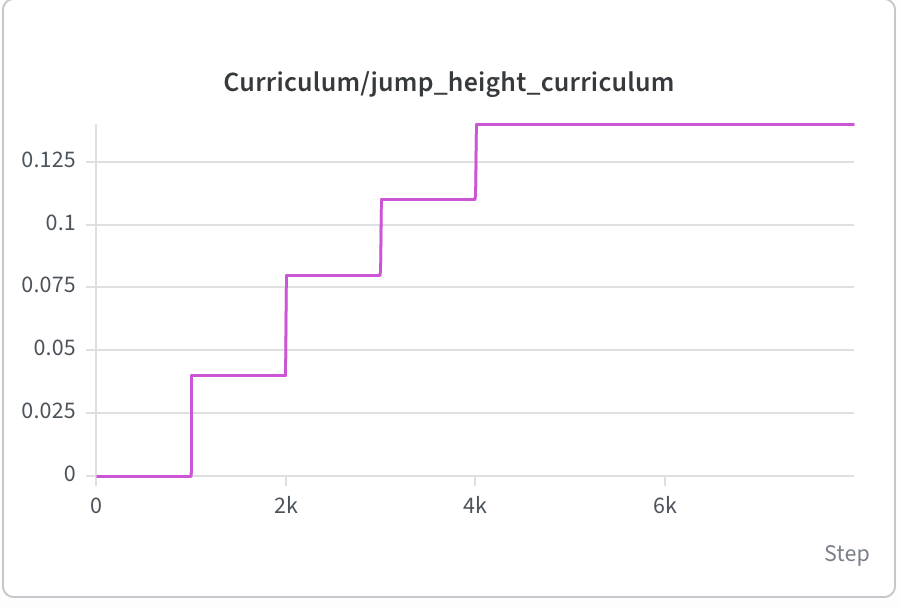

In [ ]:
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Jump-Flat-Backlash-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume False \
  --agent.max_iterations 8000 > /dev/null 2>&1

## 7. Policy Rollout & Video Rendering (WandB Checkpoint Evaluation)

### Note on Backlash Training Compute Cost (>1 Hour / 1,000 Iterations)
- **Measured Training Time**: On an NVIDIA L4 GPU (`num_envs = 4096`), `Mjlab-Jump-Flat-Backlash-MicroDuck` required **over 1 hour per 1,000 iterations (~8 hours 30 minutes for 8,000 iterations)** with higher GPU VRAM usage, compared to ~50 min / 1,000 iter for the Normal variant—even though the PPO network size (61D / 76D / 14D) is identical.
- **Why It Takes Longer**:
  1. **Stiff ±1.0° Gear-Contact Constraints**: `robot_walk_backlash.xml` injects 14 unactuated serial hinges (`passive_*_backlash`) with stiff limit constraints (`solreflimit="0.01 1"`) that remain continuously active/colliding across all 393,216 physics substeps per iteration, driving up MuJoCo Warp's Newton and line-search solver iterations.
  2. **Expanded DOFs (`nv: 20 → 34`) & VRAM Buffers**: Doubling each leg's serial chain depth increases $O(n_v^2)\text{--}O(n_v^3)$ mass-matrix Cholesky factorization cost and enlarges the pre-allocated `4096 × njmax × nv` constraint Jacobian (`efc_J`) and per-env domain randomization buffers in GPU memory.

### Command & Parameter Breakdown
- `xvfb-run -s "-screen 0 1280x720x24"`: Creates a virtual X11 framebuffer since Google Colab lacks a physical display, enabling headless offscreen GPU rendering.
- `uv run play Mjlab-Jump-Flat-Backlash-MicroDuck` (or `Mjlab-Jump-Flat-MicroDuck` for cross-validation): Specifies the target Jump task environment to evaluate.
- `--wandb-run-path <entity/project/run_id>`: Specifies the target WandB run path (e.g., `.../ioljl7ls` for Backlash, `.../qz2adxse` for Normal).
- `--num-envs 1`: Spawns a single robot instance to ensure smooth, centered camera tracking during recording.
- `--video True --video-width 1280 --video-height 720`: Enables MP4 video recording (1920x1080 recommended for high-fidelity presentation).
- `--video-length 3500`: Total recorded rollout steps. At a 50 Hz control frequency, **3,500 steps yields exactly 70 seconds** of footage ($70\text{ s} = 3500 / 50\text{ Hz}$).
- `--no-terminations True`: **[CRITICAL] Disables standard 8-second episode timeout resets.** This is essential to rigorously demonstrate that the policy has acquired a stable, continuous limit-cycle jump without falling over 70 seconds.
- `--viewer native`: Leverages the native MuJoCo offscreen renderer.

### Technical Notes on Inference & Rendering
- **61D Shared Observation Space**: Executes closed-loop policy inference feeding the exact 61-dimensional observation vector (48D proprioception + 13D command block) required for physical hardware deployment.
- **Rendering Duration**: High-quality offscreen rendering for 3,500 frames takes approximately **45 to 60 minutes**. Please wait for the process to complete or stop after ~1 hour.
- **Output Video Location**: The rendered `.mp4` video will be saved under the `logs/rsl_rl/.../videos/` directory. You can download and preview it directly from Colab's left sidebar file explorer (📁 icon).

### ⭕️ Cross-Validation [Pattern 3]: Hardware-Targeted Model (Smooth Landing Absorption & Continuous Jump Stability Under Gear Backlash)
- **Evaluation Task**: `Mjlab-Jump-Flat-Backlash-MicroDuck` (±1.0° serial gear-play model)
- **WandB Run Path (Backlash-Trained Policy)**: `moushi21-dynasoft-corp-/mjlab_microduck/ioljl7ls`

In [ ]:
import os

# Configure GPU offscreen rendering backends (EGL)
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# Execute headless rollout and video rendering using xvfb-run and native viewer
!xvfb-run --auto-servernum --server-args="-screen 0 1920x1080x24" \
    uv run play Mjlab-Jump-Flat-Backlash-MicroDuck \
    --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/ioljl7ls \
    --num-envs 1 \
    --video True \
    --video-width 1920 \
    --video-height 1080 \
    --video-length 3500 \
    --no-terminations True \
    --viewer native

❌️ Cross-Validation: Pseudo-Sim2Real Test — Checking for Landing Chattering & Increased Fall Rate Under Unseen Gear Backlash

Target Task: `Mjlab-Jump-Flat-Backlash-MicroDuck`

Run Path (Normal-Trained Policy): `moushi21-dynasoft-corp-/mjlab_microduck/qz2adxse`

#### Observation & Analysis: Why Motion Remained Smooth Contrary to Initial Expectation
Although we initially expected the zero-backlash policy (`qz2adxse`) to suffer from severe chattering or falls when exposed to unseen ±1.0° serial gear play, **it completed the full 70-second (3,500-step) rollout smoothly with zero falls and no abnormal oscillation**, thanks to four stabilizing factors:
1. **Post-Discovery Smoothness Curriculum (`action_rate_l2: -0.01 → -0.06`)**: Tightening the action-rate penalty in Stages 3–4 suppressed high-frequency command reversals, preventing the policy from fighting inside the ±1.0° deadzone.
2. **8,000-Iteration Convergence & Domain Randomization**: Full convergence with per-env randomization (trunk/head CoM ±5 mm, BAM friction scale, encoder bias, and IMU tilt error) provided strong disturbance margins.
3. **BAM Actuator Compliance & Bilateral Support**: Inherent XL330 friction damping, the 1-step `joint_vel` observation lag, and a wide two-foot symmetric support polygon absorbed minor deadband timing errors.
4. **Remaining Caveat (Landing Foot-Slip)**: Despite smooth joint motion and zero falls, unmodeled ±1.0° × 5-joint serial slack delayed touchdown timing/angle slightly, producing noticeable **horizontal foot-slip upon landing**—confirming that the **Hardware-Targeted Backlash-trained model (`ioljl7ls`) verified above** remains safer for real floors.

In [ ]:
import os

# Configure GPU offscreen rendering backends (EGL)
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# Execute headless rollout and video rendering using xvfb-run and native viewer
!xvfb-run --auto-servernum --server-args="-screen 0 1920x1080x24" \
    uv run play Mjlab-Jump-Flat-Backlash-MicroDuck \
    --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/qz2adxse \
    --num-envs 1 \
    --video True \
    --video-width 1920 \
    --video-height 1080 \
    --video-length 3500 \
    --no-terminations True \
    --viewer native

[mdp] Patches 1-2 active: NaN-safe reward/advantage
[mdp] Patch 4 active: ONNX export filters passive_* joints
[mdp] Patch 5 active: MICRODUCK_WARM_START=1 restarts curricula after checkpoint load
[INFO]: Terminations disabled
[INFO]: Loading checkpoint: model_7999.pt (run: qz2adxse, downloaded)
/content/microduck_rl/.venv/lib/python3.12/site-packages/mjlab/entity/entity.py:149: UserWarning: Actuator config matched 14 joint(s) but the same expressions also match 7 site(s): imu, left_foot, head_camera, tof, head_imu, mouth_tip, right_foot. Add a separate config with transmission_type=TransmissionType.SITE if those should be actuated too.
  self._add_actuators()
Warp 1.12.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA L4" (22 GiB, sm_89, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.0
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon be removed from the public API. It can still be access

## 8. Playback the Rendered Video
- Play the generated rollout video directly inside the notebook.
- **Notice**: The output destination of the `.mp4` file may vary depending on the task configuration. Please search within the `logs/rsl_rl/` directory, set the appropriate `video_path`, and then play the video.

In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

# Exact file path to the rendered rollout video
# Backslash Version
# video_path = "logs/rsl_rl/jump/wandb_checkpoints/ioljl7ls/videos/play/rl-video-step-0.mp4"

# Normal Version
video_path = "logs/rsl_rl/jump/wandb_checkpoints/qz2adxse/videos/play/rl-video-step-0.mp4"

if os.path.exists(video_path):
    print(f"Loding Video: {video_path}")
    mp4_data = b64encode(open(video_path, 'rb').read()).decode()
    display(HTML(f'<video width="640" height="480" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
else:
    print(f"Video file not found. Please verify that the rendering cell completed successfully. Path: {video_path}")

Loding Video: logs/rsl_rl/jump/wandb_checkpoints/qz2adxse/videos/play/rl-video-step-0.mp4
